<h2>3. Build and fine-tune a classification model.</h2>
a. Build a basic multilayer perceptron (MLP) to perform classification based on the
concatenated features at the previous step. Fine-tune it on the supervised training set for N
epochs, like what you did in Section 2.

b. Plot the learning curves on training and validation set. After how many epochs should we
stop the training?

In [27]:
#from transformers import DistilBertTokenizer, DistilBertModel
import matplotlib.pyplot as plt
import pandas as pd
#from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.preprocessing import StandardScaler
#from sklearn.utils.class_weight import compute_class_weight
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc, precision_recall_curve, average_precision_score

import torch
from torch import nn
import torch.nn.functional as F
#from torchvision import transforms

In [28]:
# try:
#     del data, embeddings, pca, subreddits, user_sub_fraction, user_subreddit_counts, user_total_comments, X_pca
# except NameError:
#     pass

X_combined = pd.read_csv('X_combined.csv', index_col=0).iloc[:,3500:]
target_df=pd.read_csv('target_supervised.csv')
target_df = target_df.set_index('author').loc[X_combined.index].reset_index()

X_train, X_test, y_train, y_test = train_test_split(X_combined, target_df['gender'], stratify=target_df['gender'], train_size=0.85, random_state=15)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, stratify=y_train, train_size=0.7/0.85, random_state=15)

print(X_train.shape, X_val.shape, X_test.shape)

(3500, 768) (750, 768) (750, 768)


[np.float64(0.0578504578883424), np.float64(0.0024612218580884917), np.float64(0.021274707237170173), np.float64(0.14122127480606517), np.float64(0.13522193359253934), np.float64(0.10767965177427688), np.float64(0.06624474351836485), np.float64(0.0800060638231502), np.float64(0.010474167381202434), np.float64(0.0067925243455092986), np.float64(0.058032414209921834), np.float64(0.04980486932457287), np.float64(0.10632359500307673), np.float64(0.03761300544233093), np.float64(0.11247451769516857), np.float64(0.06129412979046293), np.float64(0.14942950168511743), np.float64(0.2375545121400415), np.float64(0.058491943972757386), np.float64(0.044635997164520894), np.float64(0.06962863948591462), np.float64(0.07058572676948376), np.float64(0.11807698998834572), np.float64(0.09398152899327473), np.float64(0.1499005059758368), np.float64(0.05033952209177703), np.float64(0.06805901889381133), np.float64(0.06562405809973115), np.float64(0.2463061780889705), np.float64(0.19014020416511018), np.fl

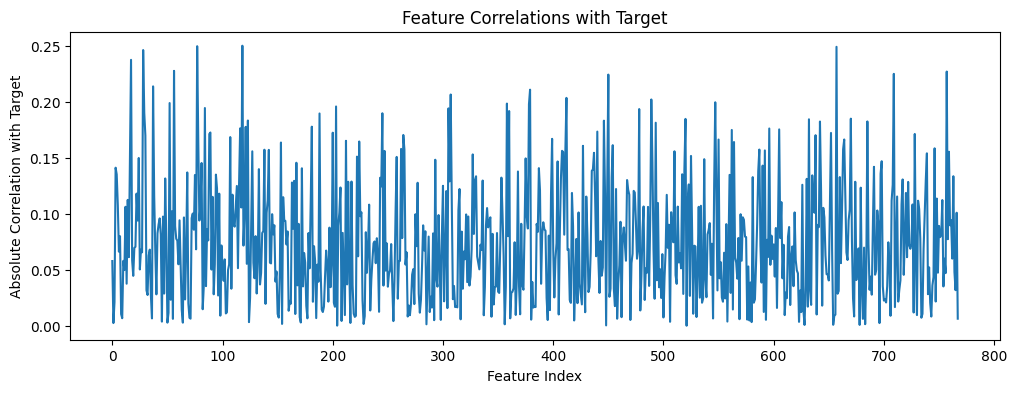

Number of features retained: 216


In [29]:
# Compute correlation between each feature and the target
correlations = []
for i, col in enumerate(X_combined.columns):
    corr = np.corrcoef(X_train.iloc[:, i].values, y_train.values)[0, 1]
    correlations.append(abs(corr))

print(correlations)
plt.figure(figsize=(12, 4))
plt.plot(correlations)
plt.xlabel('Feature Index')
plt.ylabel('Absolute Correlation with Target')
plt.title('Feature Correlations with Target')
plt.show()

# Remove features with correlation < 0.1
selected_indices = [i for i, corr in enumerate(correlations) if corr >= 0.1]
selected_columns = [X_combined.columns[i] for i in selected_indices]

# Filter columns in X_train, X_val, X_test using column names
X_train = X_train[selected_columns]
X_val = X_val[selected_columns]
X_test = X_test[selected_columns]

scaler = StandardScaler()
scaler.fit(X_train)
X_train_s, X_val_s, X_test_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

X_train = torch.tensor(X_train_s, dtype=torch.float)
y_train = torch.tensor(y_train.values, dtype=torch.long)
X_val = torch.tensor(X_val_s, dtype=torch.float)
y_val = torch.tensor(y_val.values, dtype=torch.long)
X_test = torch.tensor(X_test_s, dtype=torch.float)
y_test = torch.tensor(y_test.values, dtype=torch.long)

print(f"Number of features retained: {len(selected_columns)}")

In [30]:
# define the function that calculate the accuracy
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred))
    return acc

# function to compute and plot the confusion matrix
def confusion_matrix(y_true, y_pred):
    df = pd.DataFrame([x for x in zip([x.item() for x in y_true], [x.item() for x in y_pred])], columns=['y_true', 'y_pred'])
    df[['samples']] = 1
    confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc=sum)
    plt.figure()
    sns.heatmap(confusion, cmap='Blues', annot=True, cbar_kws={'label':'Occurrences'}, fmt='g')
    plt.xlabel('Prediction')
    plt.ylabel('True')    
    plt.title('Confusion matrix')
    plt.show()

In [31]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
        hidden_3 # number of neurons in the 3rd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer
        self.layer_3 = nn.Linear(in_features=hidden_2, out_features=hidden_3) # 3rd linear layer

        self.layer_output = nn.Linear(in_features=hidden_3, out_features=out_features) # output layer
        self.activation_1 = nn.Tanh() # activation function
        #self.activation_2 = nn.Softmax(dim=1) # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_1(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_1(self.layer_2(out)) #output of 2nd hidden layer
        out = self.activation_1(self.layer_3(out))
        #out = self.activation_2(self.layer_output(out)) #output of the nn
        out = self.layer_output(out) 
        
        return out

In [34]:
torch.manual_seed(8)
dim_features = X_train.shape[1]
model = Model_classification(
    in_features = dim_features, 
    out_features = 2, 
    hidden_1 = dim_features, 
    #hidden_1 = 1000,
    hidden_2 = int(dim_features/2),
    #hidden_2=500,
    hidden_3 = int(dim_features/4)
)

# class_weights_np = compute_class_weight(class_weight='balanced', classes=np.unique(y_train.numpy()), y=y_train.numpy())
# class_weights = torch.tensor(class_weights_np, dtype=torch.float)
# print("Class weights:", class_weights)

#loss_fn = nn.CrossEntropyLoss(weight=class_weights)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=5e-6) 

In [35]:
def create_batches(data, labels, batch_size):
    num_samples = data.shape[0]
    batches = []
    for i in range(0, num_samples, batch_size):
        data_batch = data[i:i + batch_size]
        label_batch = labels[i:i + batch_size]
        batches.append((data_batch, label_batch))
    return batches
    W
# create the batches for training set
batch_size = 64 # you can choose other batch numbers
batches = create_batches(X_train, y_train, batch_size)

In [37]:
import itertools

# Define parameter grid
# param_grid = {
#     'learning_rate': [1e-4, 5e-6],
#     'hidden_1': [dim_features, 1000],
#     'hidden_2': [int(dim_features/2), 500],
#     'hidden_3': [int(dim_features/4), 250],
#     'batch_size': [32, 64]
# }

param_grid = {
    'learning_rate': [1e-4, 1e-5, 5e-6],
    'hidden_1': [1000,  2000, 4000],
    'hidden_2': [1500, 750, 2500],
    'hidden_3': [250, 500, 1000],
    'batch_size': [32, 64]
}

# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
        hidden_3=params['hidden_3']
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)
    
    # Train for a few epochs (e.g., 5)
    for epoch in range(5):
        model.train()
        for data_batch, label_batch in batches:
            y_prob = model(data_batch)
            loss = loss_fn(y_prob, label_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    
    # Evaluate on validation set
    model.eval()
    y_prob = model(X_val)
    y_pred = torch.argmax(y_prob, dim=1)
    val_acc = accuracy_fn(y_val, y_pred)
    
    print(f"Params: {params}, Val Acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_params = params

print("Best parameters:", best_params)

Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7693
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7667
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 32}, Val Acc: 0.7627
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 64}, Val Acc: 0.7707
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 32}, Val Acc: 0.7667
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 64}, Val Acc: 0.7680
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7720
Params: {'learning_rate': 0.0001, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7653
Params: {'learning_rate'

In [38]:
best_params = {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 32}

model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
    hidden_3=best_params['hidden_3']
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 1
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

Epoch: 1 | Train Loss: 0.58019, Val Loss: 0.53400, Train Acc: 0.7571, Val Acc: 0.7307
Epoch: 2 | Train Loss: 0.50012, Val Loss: 0.49019, Train Acc: 0.7869, Val Acc: 0.7653
Epoch: 3 | Train Loss: 0.46058, Val Loss: 0.46951, Train Acc: 0.8003, Val Acc: 0.7707
Epoch: 4 | Train Loss: 0.44052, Val Loss: 0.46263, Train Acc: 0.8046, Val Acc: 0.7747
Epoch: 5 | Train Loss: 0.43061, Val Loss: 0.46170, Train Acc: 0.8083, Val Acc: 0.7733


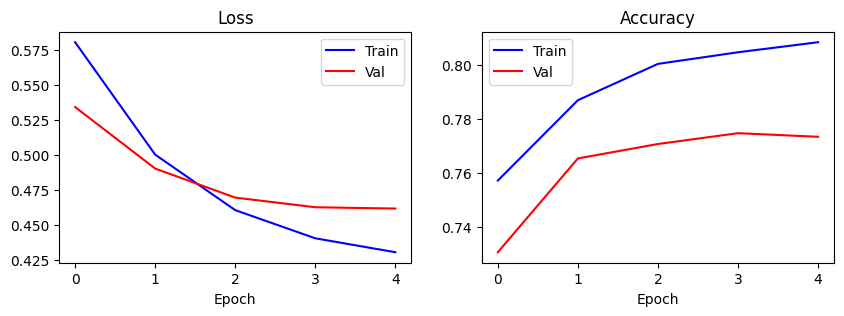

In [39]:
# visualize the evolution of losses and accuracies

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10,3))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(loss_train_all, label='Train', color='blue')
ax1.plot(loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(acc_train_all, label='Train', color='blue')
ax2.plot(acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

The accuracy is: 0.7733333333333333


/tmp/ipykernel_13041/3612716615.py:11: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc=sum)


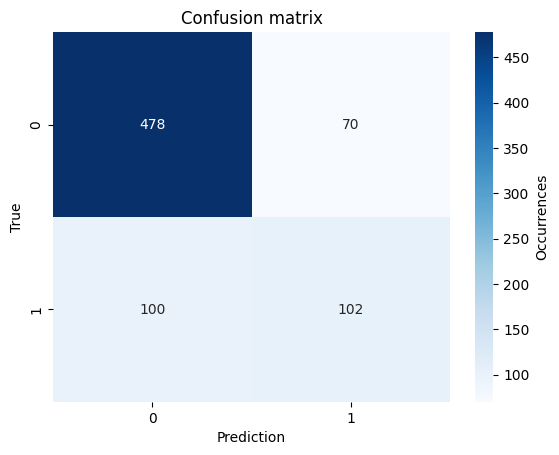

In [40]:
# visualize (final) confusion matrix on validation set

y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)

The accuracy is: 0.7826666666666666


/tmp/ipykernel_13041/3612716615.py:11: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc=sum)


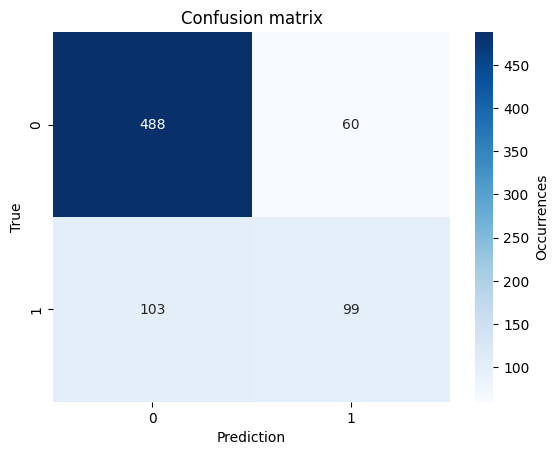

Precision: 0.6226
Recall:    0.4901
F1-score:  0.5485


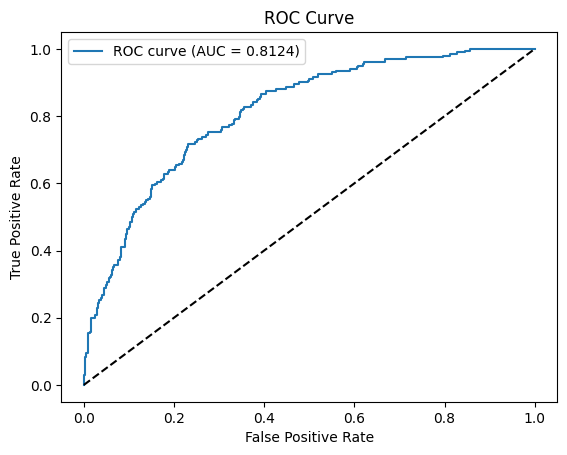

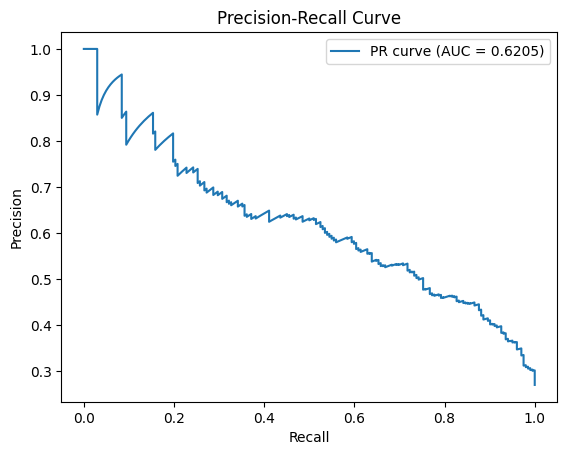

In [41]:
# visualize (final) confusion matrix on test set
y_prob = model(X_test).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_test = accuracy_fn(y_true=y_test, y_pred=y_pred)
print('The accuracy is:', acc_test)
confusion_matrix(y_test, y_pred)

# Convert torch tensors to numpy arrays
y_test_np = y_test.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='binary')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_np)
pr_auc = average_precision_score(y_test_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

Trying with a 2 layer model

In [42]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer

        self.layer_output = nn.Linear(in_features=hidden_2, out_features=out_features) # output layer
        self.activation_1 = nn.Tanh() # activation function
        #self.activation_2 = nn.Softmax(dim=1) # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_1(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_1(self.layer_2(out)) #output of 2nd hidden layer
        #out = self.activation_1(self.layer_3(out))
        #out = self.activation_2(self.layer_output(out)) #output of the nn
        out = self.layer_output(out) 
        
        return out

In [43]:
import itertools

# Define parameter grid
param_grid = {
    'learning_rate': [1e-4, 1e-5, 5e-6],
    'hidden_1': [7500, 5000, 2500],
    'hidden_2': [5000, 2500, 1250],
    'batch_size': [32, 64]
}
# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)
    
    # Train for a few epochs (e.g., 5)
    for epoch in range(5):
        model.train()
        for data_batch, label_batch in batches:
            y_prob = model(data_batch)
            loss = loss_fn(y_prob, label_batch)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    
    # Evaluate on validation set
    model.eval()
    y_prob = model(X_val)
    y_pred = torch.argmax(y_prob, dim=1)
    val_acc = accuracy_fn(y_val, y_pred)
    
    print(f"Params: {params}, Val Acc: {val_acc:.4f}")
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_params = params

print("Best parameters:", best_params)

Params: {'learning_rate': 0.0001, 'hidden_1': 7500, 'hidden_2': 5000, 'batch_size': 32}, Val Acc: 0.7693
Params: {'learning_rate': 0.0001, 'hidden_1': 7500, 'hidden_2': 5000, 'batch_size': 64}, Val Acc: 0.7600
Params: {'learning_rate': 0.0001, 'hidden_1': 7500, 'hidden_2': 2500, 'batch_size': 32}, Val Acc: 0.7667
Params: {'learning_rate': 0.0001, 'hidden_1': 7500, 'hidden_2': 2500, 'batch_size': 64}, Val Acc: 0.7520
Params: {'learning_rate': 0.0001, 'hidden_1': 7500, 'hidden_2': 1250, 'batch_size': 32}, Val Acc: 0.7733
Params: {'learning_rate': 0.0001, 'hidden_1': 7500, 'hidden_2': 1250, 'batch_size': 64}, Val Acc: 0.7533
Params: {'learning_rate': 0.0001, 'hidden_1': 5000, 'hidden_2': 5000, 'batch_size': 32}, Val Acc: 0.7680
Params: {'learning_rate': 0.0001, 'hidden_1': 5000, 'hidden_2': 5000, 'batch_size': 64}, Val Acc: 0.7560
Params: {'learning_rate': 0.0001, 'hidden_1': 5000, 'hidden_2': 2500, 'batch_size': 32}, Val Acc: 0.7707
Params: {'learning_rate': 0.0001, 'hidden_1': 5000, 'hi

In [44]:
model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 3
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

Epoch: 1 | Train Loss: 0.55468, Val Loss: 0.50795, Train Acc: 0.7780, Val Acc: 0.7467
Epoch: 2 | Train Loss: 0.46744, Val Loss: 0.47596, Train Acc: 0.8029, Val Acc: 0.7627
Epoch: 3 | Train Loss: 0.44245, Val Loss: 0.46857, Train Acc: 0.8080, Val Acc: 0.7747
Epoch: 4 | Train Loss: 0.43152, Val Loss: 0.46795, Train Acc: 0.8094, Val Acc: 0.7787
Epoch: 5 | Train Loss: 0.42520, Val Loss: 0.46923, Train Acc: 0.8131, Val Acc: 0.7787
Epoch: 6 | Train Loss: 0.42075, Val Loss: 0.47097, Train Acc: 0.8143, Val Acc: 0.7773
Epoch: 7 | Train Loss: 0.41721, Val Loss: 0.47272, Train Acc: 0.8149, Val Acc: 0.7760


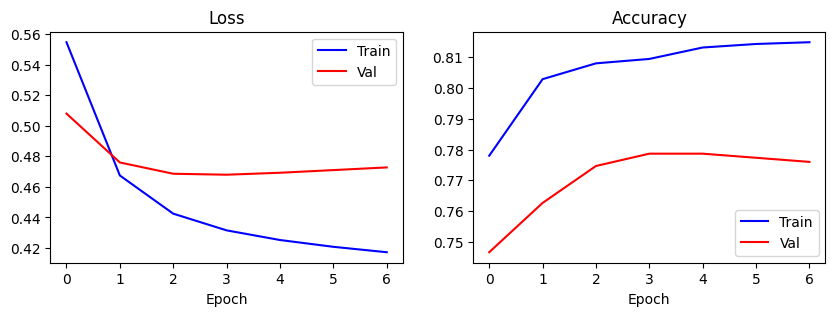

The accuracy is: 0.776


/tmp/ipykernel_13041/3612716615.py:11: FutureWarning: The provided callable <built-in function sum> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc=sum)


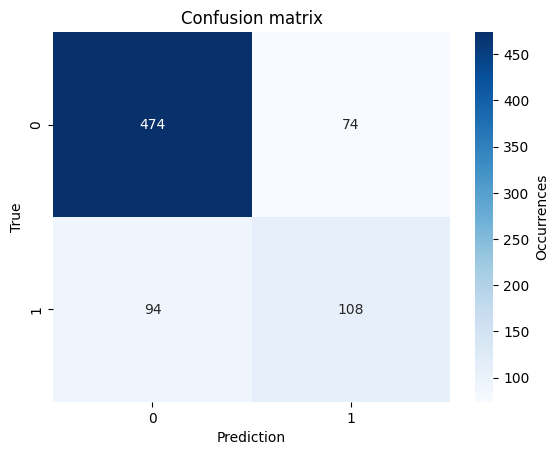

In [45]:
# visualize the evolution of losses and accuracies

fig, (ax1, ax2) = plt.subplots(1,2, figsize=(10,3))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(loss_train_all, label='Train', color='blue')
ax1.plot(loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(acc_train_all, label='Train', color='blue')
ax2.plot(acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

# visualize (final) confusion matrix on validation set
y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)